# MindEase — Mental Health Assistant with MongoDB Long-Term Memory
Every user message and AI response is stored in MongoDB Atlas.
At each turn, the full conversation history is retrieved and passed as context.

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, Literal, Annotated, List
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_community.embeddings import HuggingFaceEmbeddings
from pinecone import Pinecone
from pymongo import MongoClient
from datetime import datetime, timezone
import requests, os
from dotenv import load_dotenv
load_dotenv()

c:\Users\ASIF\anaconda3\envs\mindease_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
# ── Models ────────────────────────────────────────────────────────────────────
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-mpnet-base-v2")
groq_llm   = ChatGroq(model="llama-3.3-70b-versatile")
gemini_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

C:\Users\ASIF\AppData\Local\Temp\ipykernel_8996\1091033820.py:2: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-mpnet-base-v2")
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1202.60it/s]


In [3]:
# ── Pinecone RAG ──────────────────────────────────────────────────────────────
pc    = Pinecone(api_key=os.getenv("PINECONE_API_KEY"))
index = pc.Index("mental-health-docs")

def get_relevant_info(query: str) -> str:
    vec     = embeddings.embed_query(query)
    results = index.query(top_k=3, vector=vec, include_metadata=True, include_values=False)
    return "".join(r["metadata"]["text"] for r in results["matches"])

In [4]:
# ── Tavily Web Search ─────────────────────────────────────────────────────────
web_search_tool = TavilySearchResults(max_results=3)

C:\Users\ASIF\AppData\Local\Temp\ipykernel_8996\967636647.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  web_search_tool = TavilySearchResults(max_results=3)


## MongoDB Memory Layer
Stores every `(user_message, ai_response)` pair per user.
History is retrieved at every turn and injected into the system prompt.

In [5]:
# ── MongoDB Memory Setup ──────────────────────────────────────────────────────
MONGODB_URI = os.getenv("MONGODB_URI")
DB_NAME     = os.getenv("DB_NAME", "mindease_db")

mongo_client     = MongoClient(MONGODB_URI)
memory_collection = mongo_client[DB_NAME]["conversation_memory"]

# Create index on user_id for fast retrieval
memory_collection.create_index("user_id")
print("✅ MongoDB connected — collection: conversation_memory")

✅ MongoDB connected — collection: conversation_memory


In [6]:
# ── Memory Functions with Summarization Compression ───────────────────────────

COMPRESSION_THRESHOLD = 10   # compress when stored turns exceed this
KEEP_RECENT           = 5    # always keep this many raw turns

SUMMARY_DOC_KEY = "__summary__"   # special key to store the summary document

COMPRESSION_SYSTEM_PROMPT = """You are a memory compression assistant for a mental health support chatbot called MindEase.

Your job is to merge an existing memory summary (if any) with new conversation turns
into one comprehensive, compact summary. 
If there is no existing summery then summarize the given conversation turns.

CRITICAL RULES:
- Preserve ALL personal details: name, age, location, relationships, job, health conditions
- Preserve ALL emotional history: what troubled them, what helped, breakthroughs, setbacks
- Preserve ALL preferences: communication style, topics they like/dislike, coping methods
- Preserve ALL context needed for personalization in future sessions
- Write in third-person about the user (e.g. "The user's name is Asif...")
- Be concise but NEVER omit a detail that could matter for future personalization
- Output plain text only — no bullet points, no headers, no markdown"""


def _get_summary(user_id: str) -> str | None:
    """Retrieve the stored summary document for a user, if any."""
    doc = memory_collection.find_one({
        "user_id": user_id,
        "key":     SUMMARY_DOC_KEY
    })
    return doc["summary_text"] if doc else None


def _save_summary(user_id: str, summary_text: str):
    """Upsert the summary document for a user."""
    memory_collection.update_one(
        {"user_id": user_id, "key": SUMMARY_DOC_KEY},
        {"$set": {
            "user_id":      user_id,
            "key":          SUMMARY_DOC_KEY,
            "summary_text": summary_text,
            "updated_at":   datetime.now(timezone.utc)
        }},
        upsert=True
    )


def _compress_turns(user_id: str, turns_to_compress: list, existing_summary: str | None):
    """
    Ask LLM to merge existing_summary + turns_to_compress → new summary.
    Save new summary and delete compressed raw turns from MongoDB.
    """
    # Build LLM input
    turns_text = ""
    for t in turns_to_compress:
        turns_text += f"User: {t['user_message']}\nAssistant: {t['ai_response']}\n\n"

    if existing_summary:
        llm_input = (
            f"EXISTING SUMMARY (preserve every detail):\n{existing_summary}\n\n"
            f"NEW TURNS TO MERGE IN:\n{turns_text}"
        )
    else:
        llm_input = f"CONVERSATION TURNS TO SUMMARIZE:\n{turns_text}"

    print(f"[Compress] Sending {len(turns_to_compress)} turns to LLM for compression...")

    response = groq_llm.invoke([
        SystemMessage(content=COMPRESSION_SYSTEM_PROMPT),
        HumanMessage(content=llm_input)
    ])
    new_summary = response.content.strip()

    # Save updated summary
    _save_summary(user_id, new_summary)

    # Delete only the turns that were compressed — by their exact MongoDB _id
    compressed_ids = [t["_id"] for t in turns_to_compress]
    delete_result  = memory_collection.delete_many(
        {"_id": {"$in": compressed_ids}}
    )

    print(f"[Compress] Deleted {delete_result.deleted_count} raw turns from MongoDB")

    if delete_result.deleted_count != len(turns_to_compress):
        print(f"[Compress] ⚠️  Mismatch! Expected to delete {len(turns_to_compress)} "
              f"but deleted {delete_result.deleted_count}")

    return new_summary


def save_turn_to_memory(user_id: str, user_message: str, ai_response: str):
    """
    Save one conversation turn to MongoDB.
    Raw turns are identified by absence of 'key' field.
    """
    memory_collection.insert_one({
        "user_id":      user_id,
        "user_message": user_message,
        "ai_response":  ai_response,
        "timestamp":    datetime.now(timezone.utc)
        # deliberately no 'key' field — distinguishes raw turns from summary doc
    })


def load_history_from_memory(user_id: str) -> str:
    """
    Load conversation context for the LLM:
      - Summary of all old compressed turns (if exists)
      - Last KEEP_RECENT raw turns in full
    Returns a single formatted string to inject into the system prompt.
    """
    parts = []

    # 1. Load summary of old turns
    summary = _get_summary(user_id)
    if summary:
        parts.append(f"=== Memory summary (older conversations) ===\n{summary}")

    # 2. Load latest KEEP_RECENT raw turns
    recent_turns = list(
        memory_collection
        .find({"user_id": user_id, "key": {"$exists": False}})
        .sort("timestamp", -1)
        .limit(KEEP_RECENT)
    )
    recent_turns.reverse()  # chronological order

    if recent_turns:
        lines = []
        for t in recent_turns:
            lines.append(f"User: {t['user_message']}")
            lines.append(f"Assistant: {t['ai_response']}")
            lines.append("")
        parts.append("=== Recent conversation ===\n" + "\n".join(lines))

    if not parts:
        return "No previous conversation history."

    return "\n\n".join(parts)


def clear_memory(user_id: str):
    """Wipe all memory and summary for a user."""
    result = memory_collection.delete_many({"user_id": user_id})
    print(f"Cleared {result.deleted_count} documents for {user_id}")


def inspect_memory(user_id: str):
    """Debug helper — print current memory state for a user."""
    summary = _get_summary(user_id)
    raw_count = memory_collection.count_documents({
        "user_id": user_id, "key": {"$exists": False}
    })
    print(f"\n{'='*50}")
    print(f"User: {user_id}")
    print(f"Raw turns stored: {raw_count}")
    print(f"Summary exists: {summary is not None}")
    if summary:
        print(f"\nSummary:\n{summary}")
    print(f"{'='*50}\n")


print("✅ Memory functions with compression ready")

✅ Memory functions with compression ready


## Pydantic Schemas (unchanged from your original)

In [7]:
# ── Message Type Schema ───────────────────────────────────────────────────────
class MessageType(BaseModel):
    emotional_sharing:     Literal['yes', 'no'] = Field(
        description="User is expressing personal feelings, distress, pain, sadness, fear, anxiety, trauma, loneliness, hopelessness, or any emotional experience — even if subtle or indirect."
    )
    general_conversation:  Literal['yes', 'no'] = Field(
        description="Casual chat, greetings, small talk, or factual non-emotional exchange with no mental health relevance."
    )
    mentalHealth_question: Literal['yes', 'no'] = Field(
        description="User is asking for information, explanation, or advice about a mental health topic, condition, therapy, or coping strategy."
    )
    confidence:            float = Field(
        description="Classification confidence from 0.0 to 1.0"
    )


# ── Emotion Detection Schema ──────────────────────────────────────────────────
class EmotionDetection(BaseModel):
    mental_state: Literal[
        'normal', 'Personality disorder', 'SuicidalThought', 'addiction',
        'EatingDisorder', 'Bipolar disorder', 'depression', 'Psychotic disorder',
        'anxiety', 'stress', 'ADHD', 'Compulsive disorder', 'loneliness',
        'Post-trauma disorder'
    ] = Field(description="Primary detected mental state")

    secondary_state: Literal[
        'none', 'Personality disorder', 'SuicidalThought', 'addiction',
        'EatingDisorder', 'Bipolar disorder', 'depression', 'Psychotic disorder',
        'anxiety', 'stress', 'ADHD', 'Compulsive disorder', 'loneliness',
        'Post-trauma disorder'
    ] = Field(description="Secondary co-occurring mental state if present, else 'none'")

    severity: Literal['mild', 'moderate', 'severe', 'crisis'] = Field(
        description="Severity level of the detected mental state"
    )

    crisis_risk: Literal['none', 'low', 'medium', 'high', 'immediate'] = Field(
        description="Risk level for self-harm or suicide. 'immediate' means direct suicidal expression."
    )

    emotional_tone: Literal[
        'hopeless', 'fearful', 'angry', 'sad', 'numb', 'overwhelmed',
        'confused', 'isolated', 'ashamed', 'calm', 'neutral'
    ] = Field(description="Dominant emotional tone in the user's message")

    key_concern: str = Field(
        description="One concise sentence describing the user's core concern or pain point"
    )

    confidence: float = Field(
        description="Detection confidence from 0.0 to 1.0"
    )
    
class Quotations(BaseModel):
    quotations: List[str] = Field(description="3 to 5 short motivational quotes that are relevant to current user mental state")

class CheckRelevancy(BaseModel):
    context_relevancy: Literal['yes','no'] = Field(description="Is context relevant to user message?")
    relevancy_score:   float               = Field(description="Relevancy score 0.0 to 1.0")

## Graph State — now includes `user_id` and `conversation_history`

In [8]:
class GraphState(TypedDict):
    # ── Identity ──────────────────────────────────────────────
    user_id:               str          # who is talking
    conversation_history:  str          # loaded from MongoDB at start

    # ── Current turn ─────────────────────────────────────────
    user_message:          str

    # ── Routing & analysis ────────────────────────────────────
    message_type:          MessageType
    mental_state:          EmotionDetection
    check_relevancy:       CheckRelevancy

    # ── Intermediate outputs ──────────────────────────────────
    fine_tuned_model_response: str
    quotations:            Quotations
    relevant_info:         str

    # ── Final responses (one will be set depending on route) ──
    friendly_response:     str
    questionare_response:  str
    general_response:      str

    # ── The final answer to return and save ──────────────────
    final_response:        str

## Node 0 — Load Memory from MongoDB
This runs FIRST for every message. It pulls history and puts it in state.

In [9]:
def load_memory_node(state: GraphState):
    """
    Fetch conversation history from MongoDB for this user.
    Injects it into state as 'conversation_history' string.
    """
    user_id = state.get("user_id", "default_user")
    history = load_history_from_memory(user_id)
    print(f"[Memory] Loaded history for {user_id}")
    return {"conversation_history": history}

## Routing Node

In [10]:
llm_with_message_type = groq_llm.with_structured_output(MessageType)

def message_type_router(state: GraphState):
    user_message = state["user_message"]
    try:
        message_type = llm_with_message_type.invoke(user_message)
        if message_type.emotional_sharing    == 'yes': return "emotional_meesage"
        elif message_type.general_conversation == 'yes': return "general_conversation"
        elif message_type.mentalHealth_question == 'yes': return "questional_message"
        else: return "general_conversation"
    except Exception:
        return "general_conversation"

## Emotional Path Nodes — all receive conversation_history in prompts

In [11]:
llm_with_EmotionDetection = gemini_llm.with_structured_output(EmotionDetection)

def emotion_detection(state: GraphState):
    user_message = state["user_message"]
    history      = state.get("conversation_history", "")

    SYS_Prompt = """You are an expert in detecting mental health condition of a user.
    Analyse the user's current message AND conversation history to detect mental state."""

    mental_state = llm_with_EmotionDetection.invoke([
        SystemMessage(content=SYS_Prompt),
        HumanMessage(content=f"{history}\n\nCurrent message: {user_message}")
    ])
    return {"mental_state": mental_state}

In [12]:
def Fine_Tuned_Model(state: GraphState):
    user_message = state["user_message"]
    API_URL = "https://a-asif-mindease.hf.space/predict"
    try:
        response = requests.post(API_URL, json={"text": str(user_message)}, timeout=15)
        response = response.json()["response"]
    except Exception:
        response = "Please be kind to yourself. You are not alone in this."
    return {"fine_tuned_model_response": response}

In [13]:
llm_with_quotation_generator = gemini_llm.with_structured_output(Quotations)

def quotation_generator(state: GraphState):
    user_message = state["user_message"]
    mentalState  = state["mental_state"].mental_state

    try:
        result      = web_search_tool.invoke(f"{mentalState} mental health best quotes")
        web_results = [res["content"] for res in result]
    except Exception:
        web_results = []

    SYS_Prompt = """Generate 3 to 5 short motivational quotations based on user's mental state.
    Return only quotes, one per line, with author if confident."""

    response = llm_with_quotation_generator.invoke([
        SystemMessage(content=SYS_Prompt),
        HumanMessage(content=f"Mental State: {mentalState}\nUser: {user_message}\nWeb: {web_results}")
    ])
    return {"quotations": response}

In [14]:
def friendly_response(state: GraphState):
    user_message   = state["user_message"]
    history        = state.get("conversation_history", "")
    mentalState    = state["mental_state"].mental_state
    quotations     = state["quotations"].quotations
    ft_response    = state["fine_tuned_model_response"]

    SYS_Prompt = """You are an Expert Mental Health Psychologist Agent.
    You will receive:
    - Full conversation history with this user (use it to be personalized)
    - Their current message and detected mental state
    - Relevant motivational quotes
    - A safe response from a fine-tuned model

    Give a short, calm, structured, friendly and supportive response.
    Include quotes where suitable. Mitigate harmful states gently.
    NEVER be robotic. Use the history to feel like a continuous relationship."""

    response = groq_llm.invoke([
        SystemMessage(content=SYS_Prompt),
        HumanMessage(content=(
            f"{history}\n\n"
            f"Current Message: {user_message}\n"
            f"Mental State: {mentalState}\n"
            f"Quotes: {quotations}\n"
            f"Fine-tuned response: {ft_response}"
        ))
    ])

    answer = response.content
    return {"friendly_response": answer, "final_response": answer}

## Question Path Nodes

In [15]:
def getting_context(state: GraphState):
    relevant_text = get_relevant_info(query=str(state["user_message"]))
    return {"relevant_info": relevant_text}

llm_with_relevancy_check = gemini_llm.with_structured_output(CheckRelevancy)

def checking_context_relevancy(state: GraphState):
    SYS = """Check whether the given context is relevant to the user message.
    Be honest. Return context_relevancy and relevancy_score (0.0-1.0)."""
    result = llm_with_relevancy_check.invoke([
        SystemMessage(content=SYS),
        HumanMessage(content=f"Message: {state['user_message']}\nContext: {state['relevant_info']}")
    ])
    return {"check_relevancy": result}

def relevancy_router(state: GraphState):
    r = state["check_relevancy"]
    return "relevant" if r.context_relevancy == 'yes' and r.relevancy_score > 0.4 else "irrelevant"

def web_search(state: GraphState):
    results = web_search_tool.invoke(str(state["user_message"]))
    context = "".join(r["content"] + "\n\n" for r in results[:2])
    return {"relevant_info": context}

def questionare_response(state: GraphState):
    user_message = state["user_message"]
    history      = state.get("conversation_history", "")
    context      = state["relevant_info"]

    SYS_Prompt = """You are an expert mental health Q&A assistant.
    Use the conversation history to personalise your answer.
    Use the context and your knowledge. Be clean, short and structured."""

    response = groq_llm.invoke([
        SystemMessage(content=SYS_Prompt),
        HumanMessage(content=f"{history}\n\nQuestion: {user_message}\nContext: {context}")
    ])
    answer = response.content
    return {"questionare_response": answer, "final_response": answer}

## General Response Node

In [16]:
def general_response(state: GraphState):
    user_message = state["user_message"]
    history      = state.get("conversation_history", "")

    SYS_Prompt = """You are a Personalized Mental Health Assistant.
    You have memory of past conversations with this user — use it to be personal and warm.
    Give a friendly, interactive, short and clean response."""

    try:
        response = groq_llm.invoke([
            SystemMessage(content=SYS_Prompt),
            HumanMessage(content=f"{history}\n\nCurrent message: {user_message}")
        ])
        answer = response.content
    except Exception:
        answer = (
            "I'm having trouble connecting right now. "
            "If this feels urgent, please contact a trusted person or emergency services."
        )

    return {"general_response": answer, "final_response": answer}

## Node — Save Memory to MongoDB
This runs LAST after every response. Saves the turn to Atlas.

In [17]:
def save_memory_node(state: GraphState):
    """
    After every response:
    1. Save current turn to MongoDB
    2. Count raw turns
    3. If raw turns > COMPRESSION_THRESHOLD → compress
    """
    user_id      = state.get("user_id", "default_user")
    user_message = state.get("user_message", "")
    ai_response  = state.get("final_response", "")

    if not user_message or not ai_response:
        print("[Memory] ⚠️  Skipped save — empty message or response")
        return {}

    # ── Step 1: Save current turn ─────────────────────────────────────────────
    save_turn_to_memory(user_id, user_message, ai_response)

    # ── Step 2: Count ONLY raw turns (exclude summary doc) ───────────────────
    raw_turn_count = memory_collection.count_documents({
        "user_id": user_id,
        "key":     {"$exists": False}
    })
    existing_summary = _get_summary(user_id)

    print(f"[Memory] Saved turn | user={user_id} | "
          f"raw_turns={raw_turn_count} | "
          f"summary_exists={existing_summary is not None} | "
          f"threshold={COMPRESSION_THRESHOLD}")

    # ── Step 3: Compress if needed ────────────────────────────────────────────
    if raw_turn_count > COMPRESSION_THRESHOLD:
        print(f"[Memory] 🗜️  Compression triggered — "
              f"{raw_turn_count} raw turns > threshold {COMPRESSION_THRESHOLD}")

        # Fetch ALL raw turns oldest → newest
        all_raw_turns = list(
            memory_collection
            .find({"user_id": user_id, "key": {"$exists": False}})
            .sort("timestamp", 1)
        )

        # Verify count matches (sanity check)
        if len(all_raw_turns) <= KEEP_RECENT:
            print(f"[Memory] ⚠️  Not enough turns to compress "
                  f"(found {len(all_raw_turns)}, need > {KEEP_RECENT})")
            return {}

        # Split: compress old, keep recent
        turns_to_compress = all_raw_turns[:-KEEP_RECENT]
        turns_to_keep     = all_raw_turns[-KEEP_RECENT:]

        print(f"[Memory] Compressing {len(turns_to_compress)} turns | "
              f"Keeping {len(turns_to_keep)} raw | "
              f"Merging with existing summary: {existing_summary is not None}")

        # Run compression
        new_summary = _compress_turns(user_id, turns_to_compress, existing_summary)

        # Verify result
        remaining_raw = memory_collection.count_documents({
            "user_id": user_id,
            "key":     {"$exists": False}
        })
        print(f"[Memory] ✅ Compression done | "
              f"New raw count: {remaining_raw} | "
              f"Summary length: {len(new_summary)} chars")
    else:
        turns_until_compression = COMPRESSION_THRESHOLD - raw_turn_count + 1
        print(f"[Memory] No compression needed — "
              f"{turns_until_compression} turn(s) until next compression")

    return {}

## Build the Graph

In [18]:
builder = StateGraph(GraphState)

# ── Register nodes ────────────────────────────────────────────────────────────
builder.add_node("load_memory",               load_memory_node)
builder.add_node("emotion_detection",         emotion_detection)
builder.add_node("Fine_Tuned_Model",          Fine_Tuned_Model)
builder.add_node("quotation_generator",       quotation_generator)
builder.add_node("friendly_response",         friendly_response)
builder.add_node("getting_context",           getting_context)
builder.add_node("checking_context_relevancy",checking_context_relevancy)
builder.add_node("web_search",                web_search)
builder.add_node("questionare_response",      questionare_response)
builder.add_node("general_response",          general_response)
builder.add_node("save_memory",               save_memory_node)

# ── START → load_memory (always first) ───────────────────────────────────────
builder.add_edge(START, "load_memory")

# ── load_memory → route by message type ──────────────────────────────────────
builder.add_conditional_edges(
    "load_memory",
    message_type_router,
    {
        "emotional_meesage":  "emotion_detection",
        "general_conversation": "general_response",
        "questional_message": "getting_context",
    }
)

# ── Emotional path ────────────────────────────────────────────────────────────
builder.add_edge("emotion_detection",   "Fine_Tuned_Model")
builder.add_edge("Fine_Tuned_Model",    "quotation_generator")
builder.add_edge("quotation_generator", "friendly_response")
builder.add_edge("friendly_response",   "save_memory")   # ← save before END

# ── Question path ─────────────────────────────────────────────────────────────
builder.add_edge("getting_context", "checking_context_relevancy")
builder.add_conditional_edges(
    "checking_context_relevancy",
    relevancy_router,
    {"relevant": "questionare_response", "irrelevant": "web_search"}
)
builder.add_edge("web_search",           "questionare_response")
builder.add_edge("questionare_response", "save_memory")  # ← save before END

# ── General path ──────────────────────────────────────────────────────────────
builder.add_edge("general_response", "save_memory")      # ← save before END

# ── save_memory → END (always last) ──────────────────────────────────────────
builder.add_edge("save_memory", END)

graph = builder.compile()
print("✅ Graph compiled")

✅ Graph compiled


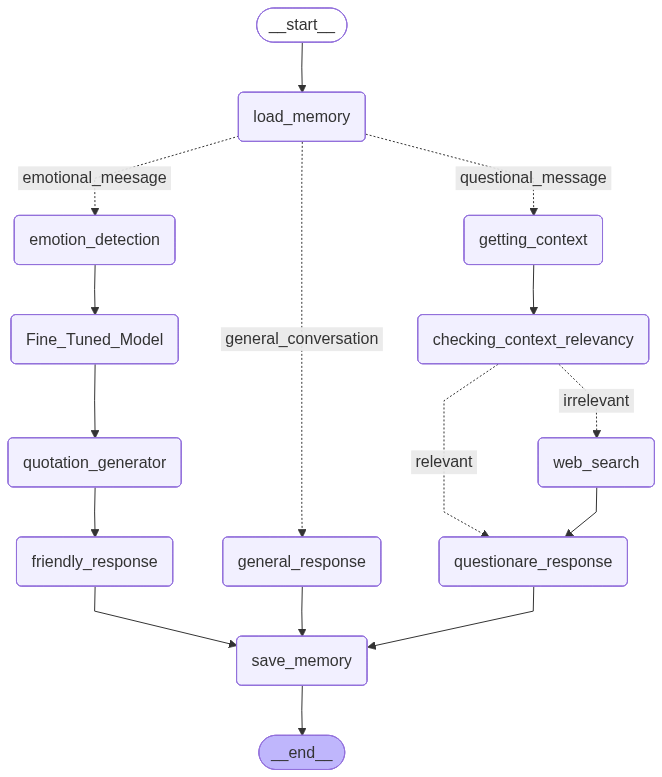

In [19]:
from IPython.display import display, Image
display(Image(graph.get_graph().draw_mermaid_png()))

## Helper — Chat Function
Pass `user_id` so each user gets their own memory namespace.

In [20]:
def chat(user_message: str, user_id: str = "user_001") -> str:
    """
    Send a message and get a response.
    Memory is automatically loaded before and saved after.
    """
    result = graph.invoke({
        "user_id":      user_id,
        "user_message": user_message,
    })
    return result.get("final_response", "(no response)")

## Test — Session 1

In [36]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("Hi, my name is Asif.", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Hi Asif, it's nice to meet you. I'm here to listen and support you with any mental health topics you'd like to discuss. How are you feeling today?


In [37]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("Hi, do yo know me?.", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Hi Asif, yes I do. We just spoke earlier and I'm happy to see you again. How's your day been since we last chatted?


In [38]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("what are causes of stress?.", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Hello again Asif, I'm glad you asked about the causes of stress. The main causes of stress include work pressure, financial struggles, relationship conflicts, health issues, family responsibilities, academic pressure, and major life transitions. Even positive events like marriage or promotions can be stressful. It's essential to identify your specific stress triggers to manage them better. Would you like to talk about what's been stressing you out lately?


In [40]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("best ways to get rid of stress", user_id="asif_001")

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001


In [44]:
print("AI:", response)

AI: Hi Asif, I see we've discussed stress and its causes earlier. To get rid of stress, here are some effective ways:

1. **Volunteer**: Helping others can give you a sense of purpose and fulfillment.
2. **Journaling**: Writing down your thoughts can help you process and release stress.
3. **Laughter**: Finding humor in life can boost your mood and reduce stress.
4. **Smile**: Simple acts like smiling can relax your body and calm your mind.
5. **Learn to deal with stress**: Accept that stress is a part of life and develop coping mechanisms, like journaling or talking to someone.

Remember, everyone is unique, so try a few methods to see what works best for you. How do you feel about trying one of these methods, Asif?


In [45]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("hey what's up?", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Hey Asif, not much. Just here to support you. We've been discussing stress and ways to manage it. How's your stress level today? Have you tried any of the methods we talked about earlier?


In [46]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("how to prevent someone from sucidal thoughts", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Asif, I'm so glad you're thinking about how to support others. Preventing suicidal thoughts requires a compassionate and non-judgmental approach. Here are some ways to help:

1. **Listen without judgment**: Allow the person to express their feelings without interrupting or judging.
2. **Encourage open conversation**: Create a safe space for them to talk about their emotions and thoughts.
3. **Help them connect with resources**: Suggest professional help, support groups, or hotlines like the National Suicide Prevention Lifeline (1-800-273-TALK).
4. **Foster a sense of belonging**: Help them stay connected with friends, family, or community to reduce feelings of isolation.
5. **Watch for warning signs**: Be aware of changes in behavior, mood, or speech that may indicate suicidal thoughts.

Remember, Asif, you're not alone in this. If you're concerned about someone, it's essential to seek professional help together.

In [47]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("lonliness is not good or not", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Asif, I'm glad you brought this up. Loneliness can be really tough to deal with. It's not good for our mental or emotional well-being. Chronic loneliness can lead to feelings of isolation, disconnection, and even depression. It's essential to address loneliness by building and maintaining social connections, engaging in activities that bring us joy, and reaching out to others when we need support. We've talked about stress and ways to manage it earlier, and I think it's great that you're thinking about the importance of social connections. Would you like to talk about what's been making you feel lonely lately, or maybe we can brainstorm some ideas to help you feel more connected?


In [21]:
inspect_memory(user_id="asif_001")


User: asif_001
Raw turns stored: 7
Summary exists: True

Summary:
The user's name is Asif. Asif has been discussing various mental health topics, including stress and its causes, which include work pressure, financial struggles, relationship conflicts, health issues, family responsibilities, academic pressure, and major life transitions. Asif has also inquired about the best ways to get rid of stress, and was provided with methods such as volunteering, journaling, laughter, smiling, and learning to deal with stress. Asif has not explicitly shared their personal stress triggers or experiences, but has shown interest in understanding stress management techniques. Additionally, Asif has asked about how to prevent someone from having suicidal thoughts, and was provided with ways to help, including listening without judgment, encouraging open conversation, helping them connect with resources, fostering a sense of belonging, and watching for warning signs. Asif's communication style appears

In [49]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("can study cause depression", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Asif, we've discussed stress and loneliness earlier, and now you're wondering if studying can cause depression. Yes, studying can indeed contribute to depression, especially if it's excessive or leads to burnout. The pressure to perform well, long study hours, and lack of social interaction can take a toll on mental health. Additionally, the fear of failure, perfectionism, and uncertainty about the future can also contribute to feelings of anxiety and depression. 

Would you like to talk about your study routine and how it's affecting your mental health, or maybe we can explore some strategies to make studying less stressful and more manageable for you?


In [23]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("I think life is too bored and useless to live", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn for asif_001
AI: Asif, I remember we just talked about this, and I want you to know that I'm still here for you. It takes a lot of courage to share these feelings, and I'm glad you're reaching out. I want to remind you that you're not alone, and there are people who care about you deeply. 

Can you tell me what's changed since we last talked about this? Is there something specific that's making you feel like life is too boring and useless to live? I'm here to listen, and I want to help you find ways to make your life feel more meaningful and fulfilling. 

Remember, you're important, and your life matters. Let's work together to find a way out of this darkness, okay?


In [24]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("Hi, I am feeling a bit anxious today.", user_id="asif_002")
print("AI:", response)

[Memory] Loaded history for asif_002
[Memory] Saved turn for asif_002
AI: I'm so glad you reached out. Sorry to hear you're feeling anxious today. Would you like to talk about what's on your mind and see if we can work through it together? I'm here to listen and support you. What's been going on that's making you feel anxious?


In [77]:
def chat(user_message: str, user_id: str = "user_001") -> str:
    """
    Send a message and get a response.
    Memory is automatically loaded before and saved after.
    """
    result = graph.invoke({
        "user_id":      user_id,
        "user_message": user_message,
    })
    return result

In [78]:
# ── General conversation — memory will save this turn ─────────────────────────
response = chat("I am thinking to end my life as life is too bored and I am tired from this useless life", user_id="asif_001")


[Memory] Loaded history for asif_001
[Memory] Saved turn | user=asif_001 | raw_turns=7 | summary_exists=True | threshold=10
[Memory] No compression needed — 4 turn(s) until next compression


In [81]:
print(response['final_response'])

Asif, I'm so glad you're reaching out again, and I want you to know that I'm here for you, no matter what. I remember our previous conversations, and I can sense that you're feeling overwhelmed and disconnected from life. It takes a lot of courage to share these feelings, and I'm proud of you for being honest with me.

I want to remind you of something that Juliette Lewis once said, "The bravest thing I ever did was continuing my life when I wanted to die." You are brave, Asif, and I believe in you. I know it's hard to see right now, but things will get better. Suicidal thoughts may promise a way out, but I want to encourage you to hold on to hope. You are more resilient than you think, and asking for help is nothing to be ashamed of.

I'm here to listen and support you, and I want to help you find ways to make your life feel more meaningful and fulfilling. Remember, you matter, and there is hope even in the hardest of times. As Susanna Kaysen said, "Survival is a talent." You have sur

In [25]:
# ── Follow-up — history is retrieved and passed as context ────────────────────
response = chat("What do you remember about me?", user_id="asif_002")
print("AI:", response)

[Memory] Loaded history for asif_002
[Memory] Saved turn for asif_002
AI: I remember that you reached out to me recently because you were feeling a bit anxious. You were kind enough to share your emotions with me, and I was happy to offer a listening ear and support. Unfortunately, we didn't get a chance to dive deeper into what was causing your anxiety, so I'm still here and ready to listen if you'd like to talk more about it. How are you feeling today?


In [39]:
# ── Follow-up — history is retrieved and passed as context ────────────────────
response = chat("hi, what is you capabilities ", user_id="asif_001")
print("AI:", response)

[Memory] Loaded history for asif_001
[Memory] Saved turn | user=asif_001 | raw_turns=6 | summary_exists=True | threshold=10
[Memory] No compression needed — 5 turn(s) until next compression
AI: {'user_id': 'asif_001', 'conversation_history': '=== Memory summary (older conversations) ===\nThe user\'s name is Asif. Asif has been discussing various mental health topics, including stress and its causes, which include work pressure, financial struggles, relationship conflicts, health issues, family responsibilities, academic pressure, and major life transitions. Asif has also inquired about the best ways to get rid of stress, and was provided with methods such as volunteering, journaling, laughter, smiling, and learning to deal with stress. Asif has not explicitly shared their personal stress triggers or experiences, but has shown interest in understanding stress management techniques. Additionally, Asif has asked about how to prevent someone from having suicidal thoughts, and was provided 

In [82]:
inspect_memory(user_id="asif_001")


User: asif_001
Raw turns stored: 7
Summary exists: True

Summary:
The user's name is Asif. Asif has been discussing various mental health topics, including stress and its causes, which include work pressure, financial struggles, relationship conflicts, health issues, family responsibilities, academic pressure, and major life transitions. Asif has also inquired about the best ways to get rid of stress, and was provided with methods such as volunteering, journaling, laughter, smiling, and learning to deal with stress. Asif has not explicitly shared their personal stress triggers or experiences, but has shown interest in understanding stress management techniques. Additionally, Asif has asked about how to prevent someone from having suicidal thoughts, and was provided with ways to help, including listening without judgment, encouraging open conversation, helping them connect with resources, fostering a sense of belonging, and watching for warning signs. Asif's communication style appears

## Test — Session 2 (new kernel restart simulation)
Even after restarting the kernel, memory persists in MongoDB.

In [26]:
# Simulates a completely new session — history is loaded fresh from Atlas
response = chat("How are you?", user_id="asif_002")
print("AI:", response)
# The AI should mention your name and anxiety from the previous session

[Memory] Loaded history for asif_002
[Memory] Saved turn for asif_002
AI: I'm doing well, thanks for asking, Asif. But more importantly, how about you? I recall we were in the middle of discussing your anxiety, and I'm here to listen and help if you'd like to continue our conversation. How have you been feeling since we last spoke?


## Inspect Memory Directly

In [30]:
# View all stored turns for a user
turns = list(memory_collection.find({"user_id": "asif_002"}).sort("timestamp", 1))
print(f"Total turns stored: {len(turns)}\n")
for i, t in enumerate(turns):
    print(f"Turn {i+1}:")
    print(f"  User: {t['user_message']}")
    print(f"  AI  : {t['ai_response'][:120]}...")
    print()

Total turns stored: 3

Turn 1:
  User: Hi, my name is Asif and I am feeling a bit anxious today.
  AI  : Hello Asif, it's nice to meet you. I'm so glad you reached out and shared how you're feeling today. It takes a lot of co...

Turn 2:
  User: What do you remember about me?
  AI  : Hi Asif, I remember that you reached out to me feeling a bit anxious, and we had a conversation about acknowledging and ...

Turn 3:
  User: How are you?
  AI  : I'm doing well, thanks for asking, Asif. But more importantly, how about you? I recall we were in the middle of discussi...



In [42]:
# Optional: clear memory for a user
clear_memory("asif_002")

Cleared 6 documents for asif_002


In [43]:
# View all stored turns for a user
turns = list(memory_collection.find({"user_id": "asif_002"}).sort("timestamp", 1))
print(f"Total turns stored: {len(turns)}\n")
for i, t in enumerate(turns):
    print(f"Turn {i+1}:")
    print(f"  User: {t['user_message']}")
    print(f"  AI  : {t['ai_response'][:120]}...")
    print()

Total turns stored: 0



# ***Streaming Output***

In [22]:
import sys
import time

def stream_chat(user_message: str, user_id: str = "user_001"):
    """
    Streaming chat with live token output.
    Shows pipeline progress + streams the final AI response token by token.
    """

    # ── Pipeline stage tracker ────────────────────────────────────────────────
    stage_labels = {
        "load_memory":                "📂 Loading your memory",
        "emotion_detection":          "🧠 Analysing emotional state",
        "Fine_Tuned_Model":           "🤖 Running specialist model",
        "quotation_generator":        "💬 Finding relevant quotes",
        "friendly_response":          "💙 Crafting your response",
        "getting_context":            "📚 Searching knowledge base",
        "checking_context_relevancy": "🔍 Checking relevance",
        "web_search":                 "🌐 Searching the web",
        "questionare_response":       "📝 Preparing answer",
        "general_response":           "💙 Crafting your response",
        "save_memory":                "💾 Saving to memory",
    }

    # Track which nodes have been shown
    seen_nodes  = set()
    final_response = None
    active_stage   = None

    print(f"\n{'─'*55}")

    # ── Stream graph events ───────────────────────────────────────────────────
    for event in graph.stream(
        {"user_id": user_id, "user_message": user_message},
        stream_mode="updates"
    ):
        for node_name, node_output in event.items():

            # Show pipeline stage label (once per node)
            if node_name not in seen_nodes and node_name in stage_labels:
                seen_nodes.add(node_name)

                # Clear previous stage indicator
                if active_stage:
                    sys.stdout.write(f"\r✅ {active_stage:<45}\n")
                    sys.stdout.flush()

                active_stage = stage_labels[node_name]
                sys.stdout.write(f"\r⏳ {active_stage:<45}")
                sys.stdout.flush()

            # Capture the final response when it arrives
            if "final_response" in (node_output or {}):
                final_response = node_output["final_response"]

    # Clear last stage indicator
    if active_stage:
        sys.stdout.write(f"\r✅ {active_stage:<45}\n")
        sys.stdout.flush()

    print(f"{'─'*55}\n")

    # ── Stream final response token by token ──────────────────────────────────
    if final_response:
        print("🌿 MindEase:\n")
        _stream_text(final_response)
    else:
        print("🌿 MindEase:\n(No response generated)")

    print(f"\n{'─'*55}\n")
    return final_response


def _stream_text(text: str, delay: float = 0.018):
    """
    Print text character by character for a live typing effect.
    Speeds up on whitespace, slows slightly on punctuation.
    """
    punctuation_pause = {'.': 0.12, '!': 0.12, '?': 0.12, ',': 0.05, ':': 0.05}

    i = 0
    while i < len(text):
        char = text[i]
        sys.stdout.write(char)
        sys.stdout.flush()

        # Natural rhythm
        if char in punctuation_pause:
            time.sleep(punctuation_pause[char])
        elif char == '\n':
            time.sleep(0.05)
        elif char == ' ':
            time.sleep(0.005)
        else:
            time.sleep(delay)
        i += 1

    sys.stdout.write('\n')
    sys.stdout.flush()

In [23]:
# ── Interactive REPL session ──────────────────────────────────────────────────
def run_session(user_id: str = "user_001"):
    """
    Full interactive session with streaming output.
    Type 'quit', 'exit', or 'bye' to end.
    Type 'memory' to inspect stored memory.
    Type 'clear' to wipe memory.
    """
    print(f"\n{'═'*55}")
    print("  🌿 MindEase — Mental Health Assistant")
    print(f"  Session user: {user_id}")
    print(f"{'═'*55}")
    print("  Commands: 'memory' | 'clear' | 'quit'\n")

    while True:
        try:
            user_input = input("You: ").strip()
        except (EOFError, KeyboardInterrupt):
            print("\n\nTake care. 💙")
            break

        if not user_input:
            continue

        if user_input.lower() in ("quit", "exit", "bye"):
            print("\n🌿 MindEase: Take care of yourself. I'll remember our conversation. 💙\n")
            break

        if user_input.lower() == "memory":
            inspect_memory(user_id)
            continue

        if user_input.lower() == "clear":
            confirm = input("Clear all memory? (yes/no): ").strip().lower()
            if confirm == "yes":
                clear_memory(user_id)
                print("✅ Memory cleared.\n")
            continue

        stream_chat(user_input, user_id=user_id)

In [24]:
# ── Run it ────────────────────────────────────────────────────────────────────
run_session(user_id="asif_001")


═══════════════════════════════════════════════════════
  🌿 MindEase — Mental Health Assistant
  Session user: asif_001
═══════════════════════════════════════════════════════
  Commands: 'memory' | 'clear' | 'quit'


User: asif_001
Raw turns stored: 7
Summary exists: True

Summary:
The user's name is Asif. Asif has been discussing various mental health topics, including stress and its causes, which include work pressure, financial struggles, relationship conflicts, health issues, family responsibilities, academic pressure, and major life transitions. Asif has also inquired about the best ways to get rid of stress, and was provided with methods such as volunteering, journaling, laughter, smiling, and learning to deal with stress. Asif has not explicitly shared their personal stress triggers or experiences, but has shown interest in understanding stress management techniques. Additionally, Asif has asked about how to prevent someone from having suicidal thoughts, and was provided with 